# Weight-Space Programming: a tiny, CPU-only example

**Weight-space programming** means an LLM treats a neural network's weights the way an engineer treats source code. It *reads* the numbers, works out what each part computes, and *writes* new values directly. There's **no gradient descent and no training loop**. The term comes from MIT CSAIL's November 2026 post *"Sparks of Weight-Space Programming"*, which used a frontier LLM to repair RL policies and a 0.8B-parameter language model.

This notebook reproduces the idea at a scale you can check by eye:

| | Experiment | What the LLM gets | What it must produce |
|---|---|---|---|
| 1 | **READ** | the weights of a trained net, with *no* description of the task | an explanation of what the net computes |
| 2 | **REPAIR** | a net with a planted bug, the spec, a few failing inputs, and 10 forward passes | fixed weights, changing as few numbers as possible |
| 3 | **WRITE** | a spec and an empty 2→4→1 architecture | weights written from scratch, with no training |

**The editor** is **Claude Opus 5.5**, run headless through **Claude Code** (`claude -p --model claude-opus-5-5`). Each experiment runs in its own folder under `runs/`. That folder contains only what the model may see. Claude gets the `Read` and `Write` tools, plus a `Bash` permission limited to `python forward.py ...`, a pure-Python forward pass with a call budget. Anything else is denied (`--permission-mode dontAsk`).

The networks are PyTorch models that train in seconds on a CPU.

In [1]:
import json
import matplotlib.pyplot as plt
import torch

from wsp.model import (TinyMLP, make_dataset, train, accuracy, save_weights, load_weights,
                       weights_to_dict, round_model, changed_weights, plot_decision)
from wsp.harness import run_experiment, summary, RUNS_DIR, MODEL

RERUN = False   # True = call Claude again instead of using the cached results in runs/
SEED = 0
print("editor model:", MODEL)

editor model: claude-opus-5-5


## 0. Train a tiny network the normal way

The task is the **diamond**: class 1 if and only if `|x| + |y| < 0.8`, for points in `[-1, 1]²`. The model is a 2 → 8 → 1 ReLU MLP with **33 parameters**. Weights are rounded to 3 decimals, so the JSON the LLM reads is exactly the model we evaluate.

test accuracy of trained net: 0.9980
{"hidden.weight": [[-8.27, 8.245], [-10.712, -10.484], [-0.272, 0.19], [-0.086, 9.439], [3.748, -1.507], [-0.143, -21.714], [-20.523, -0.054], [-14.689, -7.269]], "hidden.bias": [-6.256, -8.183, -0.479, -0.159, -1.199, -0.265, -0.144, 11.769], "out.weight": [[-7.78, -8.41, 0.32, -8.88, -2.915, -11.247, -15.628, 10.881]], "out.bias": [0.993]} ...


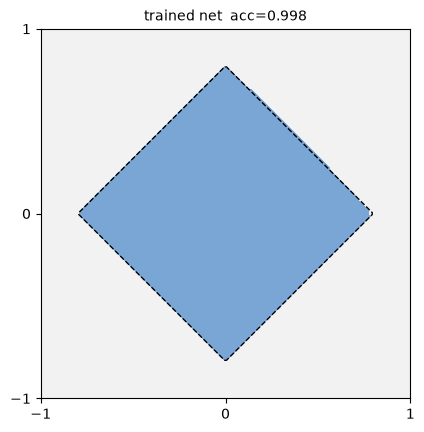

In [2]:
X_train, y_train = make_dataset("diamond", 2000, seed=0)
X_test,  y_test  = make_dataset("diamond", 20000, seed=1)

torch.manual_seed(SEED)
trained = TinyMLP(hidden=8)
train(trained, X_train, y_train, steps=4000, lr=0.02)
round_model(trained)
acc_trained = accuracy(trained, X_test, y_test)
print(f"test accuracy of trained net: {acc_trained:.4f}")
print(json.dumps(weights_to_dict(trained)["params"], indent=None)[:400], "...")

plot_decision(trained, "diamond", title=f"trained net  acc={acc_trained:.3f}")
plt.show()

## 1. READ: what does this network compute?

Claude receives only `weights.json` and the input domain. It is **not** told the task. It has no forward-pass tool, so it must reason purely from the numbers.

In [3]:
READ_PROMPT = '''You are doing weight-space programming: reasoning directly about a neural network's weights, the way an engineer reads source code.

weights.json in the current directory contains ALL the parameters of a small trained PyTorch network (the architecture is described inside the file). Inputs are points (x, y) in the square [-1, 1] x [-1, 1]; the network is a binary classifier (class 1 when logit > 0).

You cannot run the network. Reason only from the numbers.

Task: work out which region of the square the network classifies as class 1. Write your answer to answer.md containing:
1. What each hidden neuron detects (which line / half-plane activates it, in words).
2. How the output layer combines them.
3. A final one-line, closed-form description of the class-1 region, as simple as possible (e.g. a geometric shape with its size).
Keep answer.md under 60 lines.'''

read_res = run_experiment(
    "1_read", READ_PROMPT,
    files={"weights.json": json.dumps(weights_to_dict(trained), indent=2)},
    forward_budget=None, rerun=RERUN)
print(summary(read_res))

[cache] using runs\1_read\claude_result.json (rerun=True to call Claude again)
num_turns=3, duration_ms=48553, total_cost_usd=0.183454, forward_calls_used=0


In [4]:
from IPython.display import Markdown
Markdown((RUNS_DIR / "1_read" / "answer.md").read_text(encoding="utf-8"))

# Reading the network: 2 -> 8 ReLU -> 1

## 1. Hidden neurons (ReLU active when pre-activation > 0); out weight in brackets

| # | Pre-activation | Active region (in words) | out w |
|---|----------------|--------------------------|-------|
| h0 | -8.27x + 8.245y - 6.256 | upper-left corner beyond the line y - x = 0.757 | -7.78 |
| h1 | -10.71x - 10.48y - 8.18 | lower-left corner beyond the line x + y = -0.77 | -8.41 |
| h2 | -0.272x + 0.19y - 0.479 | **never** (max on square = -0.017): dead neuron | +0.32 |
| h3 | -0.086x + 9.44y - 0.159 | upper half, y > ~0.017 (≈ 9.44·relu(y)) | -8.88 |
| h4 | 3.748x - 1.507y - 1.199 | right strip, x > 0.32 + 0.40y | -2.915 |
| h5 | -0.143x - 21.71y - 0.265 | lower half, y < ~-0.012 (≈ 21.7·relu(-y)) | -11.247 |
| h6 | -20.52x - 0.054y - 0.144 | left half, x < ~-0.007 (≈ 20.5·relu(-x)) | -15.628 |
| h7 | -14.69x - 7.27y + 11.77 | almost everywhere; off only in the upper-right corner (14.69x + 7.27y > 11.77) | +10.881 |

## 2. How the output combines them

logit = 0.993 + 10.881·h7 - 15.628·h6 - 11.247·h5 - 8.88·h3 - 2.915·h4 - 7.78·h0 - 8.41·h1

- h7 is a big positive "bias" (+128 at the origin) that slopes down to the right/up:
  128 - 160x - 79y.
- h6, h5, h3 are half-axis ReLUs that turn this ramp into an absolute-value shape:
  - h6 adds +321x for x<0, flipping the x slope: -160x becomes -161|x|.
  - h3 (y>0) adds -84y, giving -163y; h5 (y<0) adds +244y, giving +165y = -165|y|.
- Result, piecewise per quadrant (all ≈ 130 - 160(|x| + |y|)):
  - Q1 (x>0, y>0): 129 - 160x - 163y
  - Q4 (x>0, y<0): 132 - 158x - 165|y|
  - Q2 (x<0, y>0): 133 - 162|x| - 162y
  - Q3 (x<0, y<0): 134 - 163|x| - 166|y|
- h0, h1, h4 are small corrections. They switch on only right at the diamond's
  edge (h0 near (0, 0.8) in Q2, h1 near (0, -0.8) in Q3, h4 near (0.8, 0)) and
  pull the boundary inward a little so that every edge lands at |x| + |y| ≈ 0.80.
- h7 switches off only in the upper-right corner, which is already outside the
  diamond. There the logit is just 0.99 minus positive terms, so it stays negative.
- h2 is dead and contributes nothing.

Check: logit(0,0) = 0.993 + 10.881·11.769 ≈ +129 (class 1). At the edges:
(0.8,0) gives ≈ 0, (0,±0.8) gives ≈ 0, (-0.8,0) gives ≈ 0. At the square's
corners the logit is strongly negative.

## 3. Class-1 region

**Class 1 ⇔ |x| + |y| < 0.8**: a diamond (a square rotated 45°) centred at the
origin, with vertices at (±0.8, 0) and (0, ±0.8). Its side is ≈ 1.13 and its
area is 1.28.


The ground truth is `|x| + |y| < 0.8`, a diamond with vertices at (±0.8, 0) and (0, ±0.8). Compare it with the last line of Claude's answer above.

## 2. REPAIR: find and fix a planted bug

We corrupt the trained net in one place. We pick the hidden neuron the decision depends on most and **flip the sign of its outgoing weight**. That's a single number out of 33. The LLM isn't told which number changed. It gets:

- the spec (the diamond),
- a handful of inputs the broken net gets wrong,
- `forward.py`, a pure-Python forward pass that prints the hidden activations, with a budget of 10 calls.

In [5]:
# choose the hidden neuron whose sign flip hurts most -> a single corrupted number
broken, worst = None, 1.0
for j in range(trained.hidden.out_features):
    cand = TinyMLP(hidden=8)
    cand.load_state_dict(trained.state_dict())
    with torch.no_grad():
        cand.out.weight[0, j] *= -1
    acc = accuracy(cand, X_test, y_test)
    if acc < worst:
        broken, worst, bug_neuron = cand, acc, j

acc_broken = accuracy(broken, X_test, y_test)
print(f"planted bug: out.weight[0][{bug_neuron}] sign flipped  (hidden by us; the LLM is not told)")
print(f"accuracy: trained {acc_trained:.4f} -> broken {acc_broken:.4f}")

# a few failing inputs to give the LLM as a bug report
with torch.no_grad():
    wrong = ((broken(X_test) > 0).float() != y_test).nonzero().flatten()[:8]
failures = [(round(X_test[i,0].item(), 2), round(X_test[i,1].item(), 2), int(y_test[i].item())) for i in wrong]
failures

planted bug: out.weight[0][6] sign flipped  (hidden by us; the LLM is not told)
accuracy: trained 0.9980 -> broken 0.6641


[(-0.94, 0.6, 0),
 (-0.37, -0.6, 0),
 (-0.98, 0.62, 0),
 (-0.95, -0.48, 0),
 (-0.53, 0.51, 0),
 (-0.53, 0.29, 0),
 (-0.96, -0.48, 0),
 (-0.65, 0.65, 0)]

In [6]:
fail_txt = "\n".join(f"  (x={x:+.2f}, y={y:+.2f}) should be class {c} but the network says class {1-c}" for x, y, c in failures)

REPAIR_PROMPT = f'''You are doing weight-space programming: debugging a neural network by reading and editing its weights directly, like source code.

weights.json in the current directory contains ALL the parameters of a small PyTorch binary classifier (architecture described inside the file). It was trained to output class 1 (logit > 0) exactly for points (x, y) in [-1, 1] x [-1, 1] with |x| + |y| < 0.8 (a diamond centred at the origin), and class 0 elsewhere.

After training, the weights were corrupted and the network now misclassifies part of the square. Bug report - some inputs it currently gets wrong:
{fail_txt}

Your job: find the fault by reading the weights and fix it by editing the numbers directly.
Rules:
- No training, no gradient descent, no optimizer, no scripts of your own. Reason about the weights.
- Create and edit files only with your Write tool. The shell is locked down: the ONLY command it accepts is
  python forward.py <weights_file> "x1,y1 x2,y2 ..."
  run on its own (no sed, no pipes, no && / ; chaining - any other command is rejected).
  forward.py prints hidden activations, logit and P(class 1) for up to 32 points per call. Budget: 10 calls in total. Use them wisely.
- Change as few numbers as possible.

Deliverables:
- repaired.json: the repaired network, same format as weights.json.
- notes.md (under 30 lines): which weight(s) you believe were corrupted, how you found them, and why your fix is correct.'''

repair_res = run_experiment(
    "2_repair", REPAIR_PROMPT,
    files={"weights.json": json.dumps(weights_to_dict(broken), indent=2)},
    forward_budget=10, rerun=RERUN)
print(summary(repair_res))
Markdown((RUNS_DIR / "2_repair" / "notes.md").read_text(encoding="utf-8"))

[claude] running claude-opus-5-5 in runs\2_repair ... (this can take a few minutes)


num_turns=6, duration_ms=48781, total_cost_usd=0.2138134, forward_calls_used=2


# Repair notes

## Corrupted weight
`out.weight[6]` (output weight of hidden neuron h6) had its sign flipped: it was **+15.628**, and the fix is **-15.628**.
This is the only number changed.

## How I found it
- I read each hidden unit as a feature:
  - h6 = relu(-20.5x - 0.14) ≈ 20.5·relu(-x), which measures "how far left" a point is.
  - h3 ≈ relu(y) and h5 ≈ relu(-y) measure "how far up" and "how far down".
  - h0 and h1 are the top-left and bottom-left diamond edges, and h4 is the right side.
  - h7 is a large-bias "inside" unit.
- To fit |x|+|y| < 0.8, every distance-from-centre feature must push the logit down. All of them have negative
  output weights (-7.78, -8.41, -8.88, -2.915, -11.247) except h6 (+15.628), which pushed the logit *up* the further left a point was.
- All 8 bug-report points have x < 0, which matches an h6 fault.
- Hand check at (-0.37, -0.60): h6 = 7.45, so its contribution is +116 and the logit is about +191 (wrong).
  With -15.628 the logit is about -42 (correct).

## Why the fix is correct
- With the sign restored, the logit along the -x axis is about 131 - 161·|x| (plus the h0/h1 edge terms), so it
  crosses 0 near |x| ≈ 0.8. This mirrors the +x side, where h7 and h4 do the same job.
- I made 2 forward.py calls on repaired.json (64 points), and every point was classified correctly:
  - All 8 bug-report points are now class 0 (logits -4 to -180).
  - Points just inside (|x|+|y| = 0.76) and just outside (= 0.84) the boundary were correct on all four edges and both
    axes. The logit changes sign between them every time (e.g. (-0.38,0.38) gives +9.5 and (-0.42,0.42) gives -8.5).
  - The centre, the corners and other interior and exterior points were also correct.


accuracy: broken 0.6641 -> repaired 0.9980  (original 0.9980)
weights changed by the LLM: 1/33; restored the original weights exactly: True


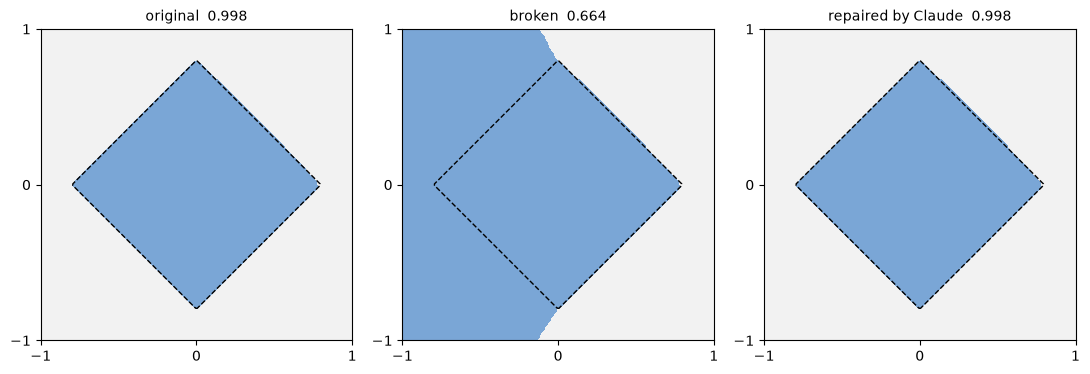

In [7]:
repaired = load_weights(RUNS_DIR / "2_repair" / "repaired.json")
acc_repaired = accuracy(repaired, X_test, y_test)
n_changed, n_total = changed_weights(broken, repaired)
restored_exactly = changed_weights(trained, repaired)[0] == 0

print(f"accuracy: broken {acc_broken:.4f} -> repaired {acc_repaired:.4f}  (original {acc_trained:.4f})")
print(f"weights changed by the LLM: {n_changed}/{n_total}; restored the original weights exactly: {restored_exactly}")

fig, axs = plt.subplots(1, 3, figsize=(11, 3.6))
plot_decision(trained,  "diamond", axs[0], f"original  {acc_trained:.3f}")
plot_decision(broken,   "diamond", axs[1], f"broken  {acc_broken:.3f}")
plot_decision(repaired, "diamond", axs[2], f"repaired by Claude  {acc_repaired:.3f}")
plt.tight_layout(); plt.show()

**Gradient baseline.** How does ordinary fine-tuning (Adam, full batch, using the 2000 training labels) do at repairing the same broken net? Fine-tuning touches (almost) every weight. The LLM used zero training examples and zero gradient steps.

In [8]:
FT_TARGET = 0.99
ft = TinyMLP(hidden=8); ft.load_state_dict(broken.state_dict())
ft_steps = train(ft, X_train, y_train, steps=5000, lr=0.01, target_acc=FT_TARGET, X_eval=X_test, y_eval=y_test)
acc_ft = accuracy(ft, X_test, y_test)
ft_changed = changed_weights(broken, ft)[0]
print(f"fine-tuning: {ft_steps} Adam steps -> accuracy {acc_ft:.4f} (target {FT_TARGET}); weights changed: {ft_changed}/{n_total}")

fine-tuning: 5000 Adam steps -> accuracy 0.9780 (target 0.99); weights changed: 29/33


## 3. WRITE: program a network from a spec

The architecture is an empty 2 → 4 → 1 ReLU net, and the spec is the **quadrant / XOR** task: class 1 if and only if `x·y > 0` (first and third quadrant). This is the classic problem a single linear layer cannot solve. Claude writes all 17 numbers. It may check them with up to 5 forward passes, but it gets no data and no training.

In [9]:
Xq_train, yq_train = make_dataset("quadrants", 2000, seed=0)
Xq_test,  yq_test  = make_dataset("quadrants", 20000, seed=1)

template = TinyMLP(hidden=4)
with torch.no_grad():
    for p in template.parameters(): p.zero_()

WRITE_PROMPT = '''You are doing weight-space programming: writing a neural network's weights by hand, like writing source code. No training of any kind.

template.json in the current directory is an all-zero network: 2 inputs (x, y) -> 4 hidden ReLU neurons -> 1 output logit (architecture described inside the file).

Spec: for every point (x, y) in [-1, 1] x [-1, 1], the logit must be > 0 when x*y > 0 (first and third quadrant) and < 0 when x*y < 0 (second and fourth quadrant). The decision boundary should coincide with the two axes as exactly as possible.

Rules:
- No training, no optimizer, no scripts of your own: design the weights by reasoning.
- You may check a weights file with:  python forward.py <weights_file> "x1,y1 x2,y2 ..."  (run it as a single standalone command; budget: 5 calls in total).

Deliverables:
- written.json: your network, same format and shapes as template.json.
- notes.md (under 20 lines): what each hidden neuron computes and why the output is correct.'''

write_res = run_experiment(
    "3_write", WRITE_PROMPT,
    files={"template.json": json.dumps(weights_to_dict(template), indent=2)},
    forward_budget=5, rerun=RERUN)
print(summary(write_res))
Markdown((RUNS_DIR / "3_write" / "notes.md").read_text(encoding="utf-8"))

[cache] using runs\3_write\claude_result.json (rerun=True to call Claude again)
num_turns=6, duration_ms=25759, total_cost_usd=0.1254456, forward_calls_used=1


# Hand-written XOR-quadrant network

Hidden neurons (all biases 0):
- h1 = relu(x + y),  h2 = relu(-x - y)  -> h1 + h2 = |x + y|
- h3 = relu(x - y),  h4 = relu(-x + y)  -> h3 + h4 = |x - y|

Output: logit = h1 + h2 - h3 - h4 = |x + y| - |x - y|  (out.bias = 0).

Why it is correct:
- |a| - |b| has the same sign as a^2 - b^2, and (x+y)^2 - (x-y)^2 = 4xy.
  So sign(logit) = sign(x*y) everywhere, not only inside [-1,1]^2.
- In closed form, logit = 2 * sign(x*y) * min(|x|, |y|).
- The zero set is exactly {x = 0} ∪ {y = 0}: the decision boundary is the two axes,
  with no approximation error. Points on the axes give logit = 0 (the spec does not
  constrain them since x*y = 0 there).
- The margin grows linearly with distance from the nearer axis (max |logit| = 2 at the corners).
  Scaling out.weight by k > 0 sharpens probabilities without moving the boundary.

Check: 20 points in 1 forward.py call (corners, near-axis points like (±0.01, 0.9),
(0.001, -1), on-axis points). Every logit had the expected sign and matched the formula.


weights written by Claude:
{
 "hidden.weight": [
  [
   1.0,
   1.0
  ],
  [
   -1.0,
   -1.0
  ],
  [
   1.0,
   -1.0
  ],
  [
   -1.0,
   1.0
  ]
 ],
 "hidden.bias": [
  0.0,
  0.0,
  0.0,
  0.0
 ],
 "out.weight": [
  [
   1.0,
   1.0,
   -1.0,
   -1.0
  ]
 ],
 "out.bias": [
  0.0
 ]
}



Claude (0 training steps): 1.0000
gradient-trained 2-4-1, 3000 Adam steps, 5 seeds: [0.9927, 0.8312, 0.9926, 0.993, 0.83]


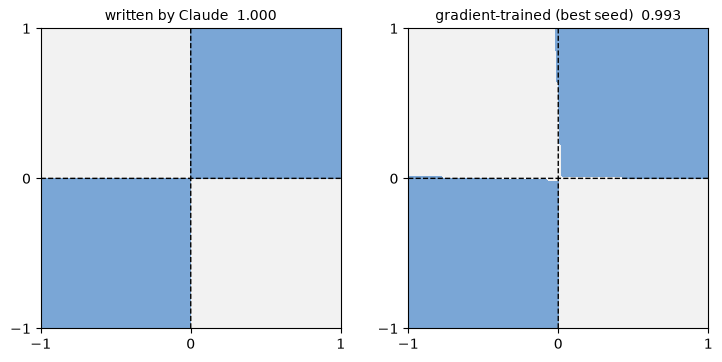

In [10]:
written = load_weights(RUNS_DIR / "3_write" / "written.json")
acc_written = accuracy(written, Xq_test, yq_test)
print("weights written by Claude:")
print(json.dumps(weights_to_dict(written)["params"], indent=1))

# baseline: train the same 2-4-1 architecture from scratch with gradients, several seeds
baseline, models = [], []
for seed in range(5):
    torch.manual_seed(seed)
    m = TinyMLP(hidden=4)
    train(m, Xq_train, yq_train, steps=3000, lr=0.02)
    baseline.append(accuracy(m, Xq_test, yq_test)); models.append(m)
print(f"\nClaude (0 training steps): {acc_written:.4f}")
print("gradient-trained 2-4-1, 3000 Adam steps, 5 seeds:", [round(a, 4) for a in baseline])

fig, axs = plt.subplots(1, 2, figsize=(7.5, 3.6))
plot_decision(written, "quadrants", axs[0], f"written by Claude  {acc_written:.3f}")
best = max(range(5), key=lambda i: baseline[i])
plot_decision(models[best], "quadrants", axs[1], f"gradient-trained (best seed)  {baseline[best]:.3f}")
plt.tight_layout(); plt.show()

## Results

In [11]:
rows = [
    ("READ",   "explain trained diamond net", "see answer.md", "-", read_res),
    ("REPAIR", "fix 1 corrupted weight",       f"{acc_broken:.3f} -> {acc_repaired:.3f}", f"{n_changed}/{n_total}", repair_res),
    ("WRITE",  "XOR/quadrants from scratch",   f"{acc_written:.3f}", "17/17 (all written)", write_res),
]
print(f"{'exp':7} {'task':30} {'test accuracy':16} {'weights changed':20} {'fwd calls':9} {'turns':5} {'cost $':7}")
for e, t, a, c, r in rows:
    print(f"{e:7} {t:30} {a:16} {c:20} {r.get('forward_calls_used',0):<9} {r.get('num_turns','-'):<5} {r.get('total_cost_usd') or 0:<7.3f}")
print(f"\ngradient baseline for REPAIR: {ft_steps} Adam steps -> {acc_ft:.3f}, {ft_changed}/{n_total} weights changed")
print(f"gradient baseline for WRITE: 3000 Adam steps, 5 seeds -> {min(baseline):.3f} .. {max(baseline):.3f}")

exp     task                           test accuracy    weights changed      fwd calls turns cost $ 
READ    explain trained diamond net    see answer.md    -                    0         3     0.183  
REPAIR  fix 1 corrupted weight         0.664 -> 0.998   1/33                 2         6     0.214  
WRITE   XOR/quadrants from scratch     1.000            17/17 (all written)  1         6     0.125  

gradient baseline for REPAIR: 5000 Adam steps -> 0.978, 29/33 weights changed
gradient baseline for WRITE: 3000 Adam steps, 5 seeds -> 0.830 .. 0.993


## Takeaways and limits

- With 33 parameters, an LLM can reliably read a network "like code": each hidden ReLU is a half-plane, and the output layer is a weighted vote.
- A **localized** bug, such as a single flipped sign, is exactly the case where weight-space programming shines. This matches the MIT finding that it works for single, local faults and struggles with distributed ones.
- Writing XOR by hand is easy for a model that knows that `|x+y| - |x-y|` has the sign of `x·y`. A gradient learner has to discover that from data.
- This is a toy. Real networks have millions or billions of parameters, and their features are not axis-aligned half-planes. The original work needed a Python sandbox and forward-pass budgets to scale.

**Ideas to extend this:** plant distributed bugs (noise on every weight), use bigger hidden layers, remove the forward-pass tool, try MNIST-scale MLPs, or compare editor models.

**Reproduce:** set `RERUN = True` at the top (this requires Claude Code to be logged in) and run all cells. Every prompt, the files Claude wrote, its forward-pass log and the run metadata are in `runs/<experiment>/`.